# Project 3 - Time Series Forecasting using Prophet
## Name: Hritik Mathur
## Course: CS675 - Introduction to Data Science

In this project, I implement a time series forecasting model using Prophet to predict New York City electricity consumption.

I test the model on three datasets:
1. Daily data
2. Monthly mean data
3. Yearly mean data

I also include the extra credit:
- forecasting for each borough independently
- ACF correlogram for the full NYC dataset and borough datasets

In [1]:
!pip install prophet statsmodels

## Step 1: Import Libraries

In this step, I import the libraries needed for:
- data handling
- graph plotting
- Prophet forecasting
- model evaluation
- ACF plotting

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from statsmodels.graphics.tsaplots import plot_acf

## Step 2: Load the Dataset

In this step, I load the NYC electricity consumption dataset.

In [3]:
df = pd.read_csv("Electric_Consumption_And_Cost_(2010_-_Sep_2025)_20260501.csv")
df.head()

,Development Name,Borough,Account Name,Location,Meter AMR,Meter Scope,TDS #,EDP,RC Code,Funding Source,...,Meter Number,Estimated,Current Charges,Rate Class,Bill Analyzed,Consumption (KWH),KWH Charges,Consumption (KW),KW Charges,Other charges
0,SHEEPSHEAD BAY,BROOKLYN,SHEEPSHEAD BAY,SHEEPSHEAD BAY BLD 11,AMR,NaN,36.0,314,K003600,FEDERAL,...,12787077,N,"$5,106.45",GOV/NYC/068,Yes,"33,001","$1,523.76",0,$0,"$3,582.69"
1,SHEEPSHEAD BAY,BROOKLYN,SHEEPSHEAD BAY,SHEEPSHEAD BAY BLD 05,AMR,NaN,36.0,314,K003600,FEDERAL,...,12786820,N,"$5,581.02",GOV/NYC/068,Yes,"36,068","$1,665.38",0,$0,"$3,915.64"
2,SHEEPSHEAD BAY,BROOKLYN,SHEEPSHEAD BAY,SHEEPSHEAD BAY BLD 18,AMR,NaN,36.0,314,K003600,FEDERAL,...,4499227,N,"$4,791.96",GOV/NYC/068,Yes,"30,969","$1,429.94",0,$0,"$3,362.02"
3,SHEEPSHEAD BAY,BROOKLYN,SHEEPSHEAD BAY,SHEEPSHEAD BAY BLD 01,AMR,NaN,36.0,314,K003600,FEDERAL,...,12787144,N,"$6,225.81",GOV/NYC/068,Yes,"40,235","$1,857.78",0,$0,"$4,368.03"
4,SHEEPSHEAD BAY,BROOKLYN,SHEEPSHEAD BAY,SHEEPSHEAD BAY BLD 08,AMR,NaN,36.0,314,K003600,FEDERAL,...,12787064,N,"$5,254.21",GOV/NYC/068,Yes,"33,956","$1,567.86",0,$0,"$3,686.35"


## Step 3: Check the Dataset Structure

This step helps identify the important columns that will be used for the project.

In [4]:
print(df.columns.tolist())
print("Shape of dataset:", df.shape)

['Development Name', 'Borough', 'Account Name', 'Location', 'Meter AMR', 'Meter Scope', 'TDS #', 'EDP', 'RC Code', 'Funding Source', 'AMP #', 'Vendor Name', 'UMIS BILL ID', 'Revenue Month', 'Service Start Date', 'Service End Date', '# days', 'Meter Number', 'Estimated', 'Current Charges', 'Rate Class', 'Bill Analyzed', 'Consumption (KWH)', 'KWH Charges', 'Consumption (KW)', 'KW Charges', 'Other charges']
Shape of dataset: (553666, 27)


## Step 4: Clean the Main Columns

I use these columns from the dataset:
- `Service Start Date`
- `Service End Date`
- `# days`
- `Consumption (KWH)`
- `Borough`

Since the raw file is billing-period data, I convert the electricity consumption to numeric form and prepare it for daily expansion.

In [5]:
df["Service Start Date"] = pd.to_datetime(df["Service Start Date"], errors="coerce")
df["Service End Date"] = pd.to_datetime(df["Service End Date"], errors="coerce")

df["Consumption (KWH)"] = (
    df["Consumption (KWH)"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

df["Consumption (KWH)"] = pd.to_numeric(df["Consumption (KWH)"], errors="coerce")
df["# days"] = pd.to_numeric(df["# days"], errors="coerce")

df = df.dropna(subset=["Service Start Date", "Service End Date", "Consumption (KWH)", "# days", "Borough"])
df = df[df["# days"] > 0]

print(df[["Service Start Date", "Service End Date", "# days", "Consumption (KWH)", "Borough"]].head())

  Service Start Date Service End Date  # days  Consumption (KWH)   Borough
0         2025-08-21       2025-09-22    32.0            33001.0  BROOKLYN
1         2025-08-21       2025-09-22    32.0            36068.0  BROOKLYN
2         2025-08-21       2025-09-22    32.0            30969.0  BROOKLYN
3         2025-08-21       2025-09-22    32.0            40235.0  BROOKLYN
4         2025-08-21       2025-09-22    32.0            33956.0  BROOKLYN


## Step 5: Convert Billing Data into Daily Data

The uploaded dataset is not already in exact daily form.
Each row represents electricity consumption over a billing period.

So I convert each row into daily average consumption:

Daily Average = Consumption (KWH) / # days

Then I spread that value across all dates from Service Start Date to Service End Date.

This creates a true daily time series, which is more correct for this project.

In [6]:
df["daily_kwh"] = df["Consumption (KWH)"] / df["# days"]

df[["Service Start Date", "Service End Date", "# days", "Consumption (KWH)", "daily_kwh"]].head()

,Service Start Date,Service End Date,# days,Consumption (KWH),daily_kwh
0,2025-08-21,2025-09-22,32.0,33001.0,1031.28125
1,2025-08-21,2025-09-22,32.0,36068.0,1127.12500
2,2025-08-21,2025-09-22,32.0,30969.0,967.78125
3,2025-08-21,2025-09-22,32.0,40235.0,1257.34375
4,2025-08-21,2025-09-22,32.0,33956.0,1061.12500


## Step 6: Build the Daily NYC Time Series

Instead of expanding every billing record into one row per day using a slow loop,
I use a faster method:

- add the daily value at the start date
- subtract it after the end date
- use cumulative sum to recover the full daily series

This gives a true daily NYC electricity time series.

In [26]:
def build_daily_series(interval_df):
    temp = interval_df[["Service Start Date", "Service End Date", "daily_kwh"]].copy()

    start_add = temp.groupby("Service Start Date")["daily_kwh"].sum()

    end_sub = temp.assign(
        end_next=temp["Service End Date"] + pd.Timedelta(days=1)
    ).groupby("end_next")["daily_kwh"].sum()

    deltas = start_add.subtract(end_sub, fill_value=0).sort_index()

    full_dates = pd.date_range(
        temp["Service Start Date"].min(),
        temp["Service End Date"].max(),
        freq="D"
    )

    daily_series = deltas.reindex(full_dates, fill_value=0).cumsum()

    expanded_daily = daily_series.reset_index()
    expanded_daily.columns = ["date", "daily_kwh"]

    expanded_daily["daily_kwh"] = expanded_daily["daily_kwh"].clip(lower=0)

    return expanded_daily

expanded_df = build_daily_series(df)
expanded_df.head()

,date,daily_kwh
0,2009-12-17,0.970588
1,2009-12-18,0.970588
2,2009-12-19,0.970588
3,2009-12-20,0.970588
4,2009-12-21,0.970588


## Step 7: Create the Final Daily NYC Dataset

Now I rename the columns into Prophet format:
- `ds` for date
- `y` for electricity consumption

In [27]:
daily_df = expanded_df.copy()

daily_df.columns = ["ds", "y"]
daily_df = daily_df.sort_values("ds")

daily_df.head()

,ds,y
0,2009-12-17,0.970588
1,2009-12-18,0.970588
2,2009-12-19,0.970588
3,2009-12-20,0.970588
4,2009-12-21,0.970588


## Step 8: Create the Monthly Mean Dataset

This dataset is created by averaging the daily electricity consumption for each month.

In [28]:
monthly_df = daily_df.copy()

monthly_df["month"] = monthly_df["ds"].dt.to_period("M")
monthly_df = monthly_df.groupby("month")["y"].mean().reset_index()

monthly_df["ds"] = monthly_df["month"].dt.to_timestamp()
monthly_df = monthly_df[["ds", "y"]]

monthly_df.head()

,ds,y
0,2009-12-01,1.709865e+06
1,2010-01-01,3.307651e+06
2,2010-02-01,3.212133e+06
3,2010-03-01,3.113377e+06
4,2010-04-01,3.016633e+06


## Step 9: Create the Yearly Mean Dataset

This dataset is created by averaging the daily electricity consumption for each year.

In [29]:
yearly_df = daily_df.copy()

yearly_df["year"] = yearly_df["ds"].dt.to_period("Y")
yearly_df = yearly_df.groupby("year")["y"].mean().reset_index()

yearly_df["ds"] = yearly_df["year"].dt.to_timestamp()
yearly_df = yearly_df[["ds", "y"]]

yearly_df.head()

,ds,y
0,2009-01-01,1.709865e+06
1,2010-01-01,3.625144e+06
2,2011-01-01,7.712934e+04
3,2012-01-01,3.605105e+06
4,2013-01-01,3.565324e+06


## Step 10: Detect the Time Unit Automatically

The project requires the code to determine whether the dataset is daily, monthly, or yearly.

In [30]:
def detect_time_unit(data):
    gap = data["ds"].sort_values().diff().dropna()
    avg_days = gap.dt.days.mean()

    if avg_days <= 2:
        return "day"
    elif avg_days <= 35:
        return "month"
    else:
        return "year"

In [31]:
print("Daily unit:", detect_time_unit(daily_df))
print("Monthly unit:", detect_time_unit(monthly_df))
print("Yearly unit:", detect_time_unit(yearly_df))

Daily unit: day
Monthly unit: month
Yearly unit: year


## Step 11: Helper Functions

These helper functions are used for:
- setting future forecast periods
- setting time frequency
- train/test splitting

In [32]:
def get_future_values(unit):
    if unit == "day":
        return [100, 200, 365]
    elif unit == "month":
        return [1, 6, 9]
    elif unit == "year":
        return [1, 10, 20]

def get_frequency(unit):
    if unit == "day":
        return "D"
    elif unit == "month":
        return "MS"
    else:
        return "YS"

def split_data(data):
    split_index = int(len(data) * 0.8)
    train_data = data.iloc[:split_index].copy()
    test_data = data.iloc[split_index:].copy()
    return train_data, test_data

## Step 12: Prophet Training Function

This function:
- creates the Prophet model
- applies growth tuning
- adds manual seasonality
- tunes changepoints
- trains the model
- predicts future values

In [33]:
def train_prophet_model(train_data, growth_type, seasonality_period, fourier_order,
                        n_changepoints, changepoint_prior_scale, freq, periods):
    
    train_copy = train_data.copy()

    if growth_type == "logistic":
        train_copy["cap"] = train_copy["y"].max() * 1.2
        train_copy["floor"] = 0

        model = Prophet(
            growth="logistic",
            n_changepoints=n_changepoints,
            changepoint_prior_scale=changepoint_prior_scale
        )
    else:
        model = Prophet(
            growth=growth_type,
            n_changepoints=n_changepoints,
            changepoint_prior_scale=changepoint_prior_scale
        )

    model.add_seasonality(
        name="custom_seasonality",
        period=seasonality_period,
        fourier_order=fourier_order
    )

    model.fit(train_copy)

    future = model.make_future_dataframe(periods=periods, freq=freq)

    if growth_type == "logistic":
        future["cap"] = train_copy["cap"].max()
        future["floor"] = 0

    forecast = model.predict(future)

    return model, forecast

## Step 13: Evaluation Function

This function evaluates the model using:
- MAE
- MAPE
- R²

In [34]:
def evaluate_model(test_data, forecast):
    merged = pd.merge(test_data, forecast[["ds", "yhat"]], on="ds", how="inner")

    mae = mean_absolute_error(merged["y"], merged["yhat"])
    mape = mean_absolute_percentage_error(merged["y"], merged["yhat"])
    r2 = r2_score(merged["y"], merged["yhat"])

    return mae, mape, r2, merged

## Step 14: Create the Plot Function

This function plots:
- historical time series
- forecasted values

In [35]:
def plot_result(original_data, forecast, title):
    plt.figure(figsize=(12, 6))
    plt.plot(original_data["ds"], original_data["y"], label="Historical Data")
    plt.plot(forecast["ds"], forecast["yhat"], label="Forecast")
    plt.xlabel("Date")
    plt.ylabel("Electric Consumption")
    plt.title(title)
    plt.legend()
    plt.show()

## Step 15: Parameter Tuning Values

The project requires tuning of:
- growth
- manual seasonality
- changepoints

I use a simple parameter list for student-level understanding.

In [36]:
param_list = [
    {"growth": "linear", "period": 7, "fourier": 5, "changepoints": 10, "cps": 0.05},
    {"growth": "linear", "period": 30.5, "fourier": 5, "changepoints": 20, "cps": 0.1},
    {"growth": "logistic", "period": 7, "fourier": 10, "changepoints": 15, "cps": 0.05},
    {"growth": "flat", "period": 365, "fourier": 3, "changepoints": 10, "cps": 0.01}
]

## Step 16: Create the Main Function to Run One Dataset

This function:
- detects the dataset unit
- splits train and test data
- tests different Prophet parameter settings
- selects the best model
- prints MAE, MAPE, and R²
- draws the historical and future graph
- prints forecast values in table form

In [37]:
def run_dataset(data, dataset_name):
    print("\n==============================")
    print("Dataset:", dataset_name)
    print("==============================")

    unit = detect_time_unit(data)
    print("Detected time unit:", unit)

    freq = get_frequency(unit)
    future_values = get_future_values(unit)

    train_data, test_data = split_data(data)

    best_mae = 999999999
    best_model = None
    best_forecast = None
    best_params = None
    best_mape = None
    best_r2 = None

    for params in param_list:
        try:
            model, forecast = train_prophet_model(
                train_data=train_data,
                growth_type=params["growth"],
                seasonality_period=params["period"],
                fourier_order=params["fourier"],
                n_changepoints=params["changepoints"],
                changepoint_prior_scale=params["cps"],
                freq=freq,
                periods=len(test_data)
            )

            mae, mape, r2, merged = evaluate_model(test_data, forecast)

            print("\nParameters:", params)
            print("MAE:", mae)
            print("MAPE:", mape)
            print("R2:", r2)

            if mae < best_mae:
                best_mae = mae
                best_model = model
                best_forecast = forecast
                best_params = params
                best_mape = mape
                best_r2 = r2

        except Exception as e:
            print("Error for parameters:", params)
            print(e)

    print("\nBest Parameters for", dataset_name)
    print(best_params)
    print("Best MAE:", best_mae)
    print("Best MAPE:", best_mape)
    print("Best R2:", best_r2)

    plot_result(data, best_forecast, dataset_name + " Forecast")

    for value in future_values:
        print("\nForecast for next", value, unit + "(s)")

        final_model, final_forecast = train_prophet_model(
            train_data=data,
            growth_type=best_params["growth"],
            seasonality_period=best_params["period"],
            fourier_order=best_params["fourier"],
            n_changepoints=best_params["changepoints"],
            changepoint_prior_scale=best_params["cps"],
            freq=freq,
            periods=value
        )

        future_table = final_forecast.tail(value)[["ds", "yhat", "yhat_lower", "yhat_upper"]]
        display(future_table)

## Step 17: Run the Model on the Three Required Datasets

14:05:02 - cmdstanpy - INFO - Chain [1] start processing



Dataset: Daily Dataset
Detected time unit: day


14:05:03 - cmdstanpy - INFO - Chain [1] done processing
14:05:03 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 7, 'fourier': 5, 'changepoints': 10, 'cps': 0.05}
MAE: 982291.4646356753
MAPE: 6.642388143904795e+20
R2: 0.2542320796282418


14:05:04 - cmdstanpy - INFO - Chain [1] done processing
14:05:05 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 866955.8255677676
MAPE: 9.208247912875014e+20
R2: 0.35317546475882877


14:05:06 - cmdstanpy - INFO - Chain [1] done processing
14:05:12 - cmdstanpy - INFO - Chain [1] start processing
14:05:12 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 1286976.8880829234
MAPE: 2.5061593468021317e+21
R2: -0.6140081377836033

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 821345.5025357835
MAPE: 1.8481559581476735e+21
R2: 0.09177244754650826

Best Parameters for Daily Dataset
{'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
Best MAE: 821345.5025357835
Best MAPE: 1.8481559581476735e+21
Best R2: 0.09177244754650826


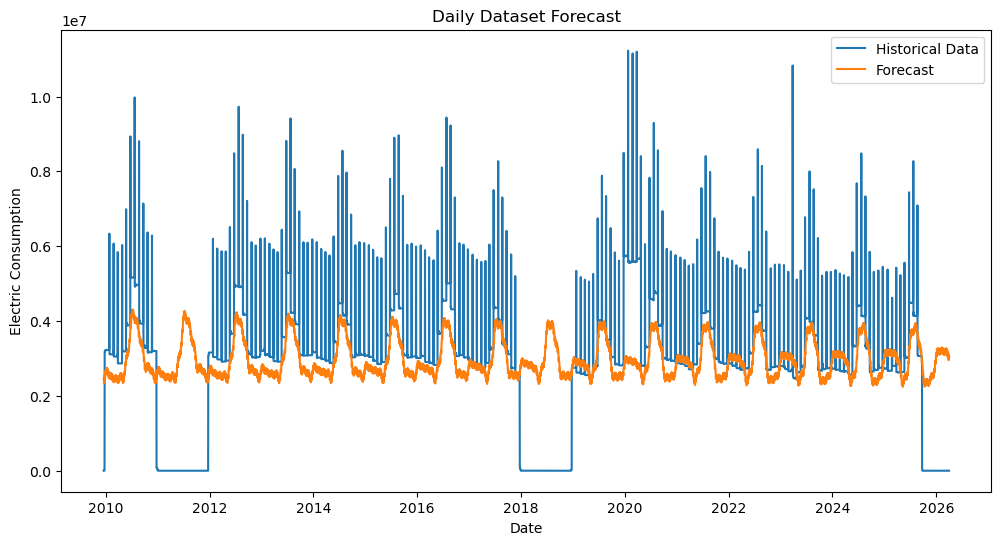

14:05:12 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 100 day(s)


14:05:12 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5950,2026-04-02,2.826158e+06,8.766962e+05,4.565836e+06
5951,2026-04-03,2.819971e+06,1.062574e+06,4.622029e+06
5952,2026-04-04,2.717529e+06,8.918076e+05,4.580315e+06
5953,2026-04-05,2.736234e+06,9.900197e+05,4.474118e+06
5954,2026-04-06,2.900355e+06,1.096068e+06,4.684113e+06
...,...,...,...,...
6045,2026-07-06,4.394498e+06,2.623656e+06,6.169251e+06
6046,2026-07-07,4.415073e+06,2.598658e+06,6.226147e+06
6047,2026-07-08,4.383481e+06,2.510876e+06,6.173658e+06
6048,2026-07-09,4.427245e+06,2.623273e+06,6.342437e+06


14:05:13 - cmdstanpy - INFO - Chain [1] start processing
14:05:13 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 200 day(s)


... (4 outputs left out)

14:05:14 - cmdstanpy - INFO - Chain [1] start processing
14:05:14 - cmdstanpy - INFO - Chain [1] done processing
14:05:14 - cmdstanpy - INFO - Chain [1] start processing
14:05:14 - cmdstanpy - INFO - Chain [1] done processing
14:05:14 - cmdstanpy - INFO - Chain [1] start processing



Dataset: Monthly Mean Dataset
Detected time unit: month

Parameters: {'growth': 'linear', 'period': 7, 'fourier': 5, 'changepoints': 10, 'cps': 0.05}
MAE: 823614.8573547011
MAPE: 2.188925027942451e+21
R2: -0.19214275589608287

Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 1901489.7238246414
MAPE: 4.113703198124851e+21
R2: -4.818542036861352


14:05:14 - cmdstanpy - INFO - Chain [1] done processing
14:05:14 - cmdstanpy - INFO - Chain [1] start processing
14:05:14 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 1168793.853318664
MAPE: 2.50919869607632e+21
R2: -0.6910931636755546

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 837681.6471058058
MAPE: 1.9139874289564375e+21
R2: 0.05727676593514808

Best Parameters for Monthly Mean Dataset
{'growth': 'linear', 'period': 7, 'fourier': 5, 'changepoints': 10, 'cps': 0.05}
Best MAE: 823614.8573547011
Best MAPE: 2.188925027942451e+21
Best R2: -0.19214275589608287


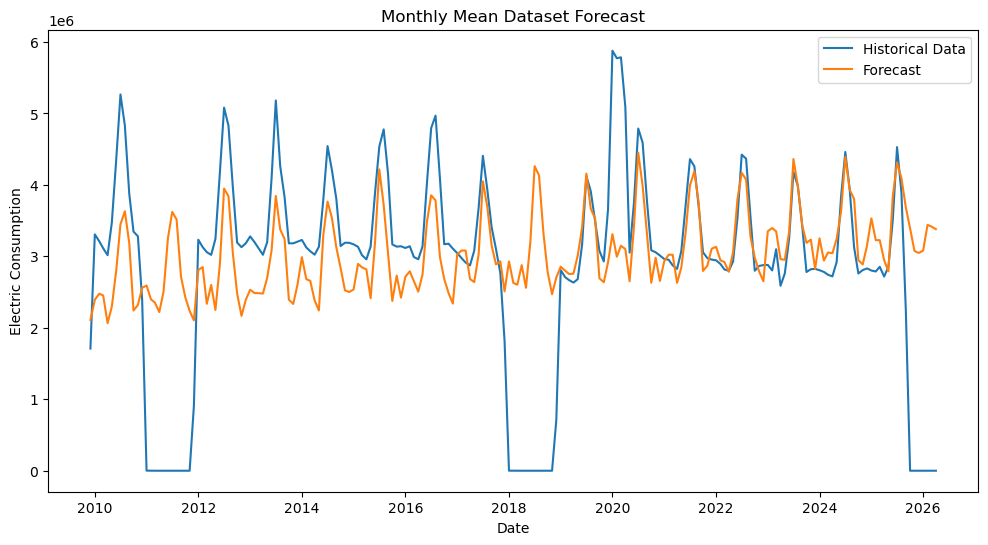

14:05:15 - cmdstanpy - INFO - Chain [1] start processing
14:05:15 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 1 month(s)


,ds,yhat,yhat_lower,yhat_upper
197,2026-05-01,2.643554e+06,992515.175188,4.283969e+06


14:05:15 - cmdstanpy - INFO - Chain [1] start processing
14:05:15 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 6 month(s)


,ds,yhat,yhat_lower,yhat_upper
197,2026-05-01,2.643554e+06,9.546593e+05,4.384811e+06
198,2026-06-01,3.243465e+06,1.535832e+06,4.822500e+06
199,2026-07-01,4.155898e+06,2.488202e+06,5.758959e+06
200,2026-08-01,3.814908e+06,2.125171e+06,5.429786e+06
201,2026-09-01,3.142218e+06,1.491103e+06,4.719670e+06
202,2026-10-01,2.269100e+06,5.224517e+05,3.902829e+06


... (8 outputs left out)

14:05:15 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 2475023.524655789
MAPE: 4.722667448170748e+21
R2: -3.394520295672269


14:05:15 - cmdstanpy - INFO - Chain [1] start processing
14:05:15 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 1355311.7616009514
MAPE: 3.927888665494697e+21
R2: -1.0532490826892116

Best Parameters for Yearly Mean Dataset
{'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
Best MAE: 1355311.7616009514
Best MAPE: 3.927888665494697e+21
Best R2: -1.0532490826892116


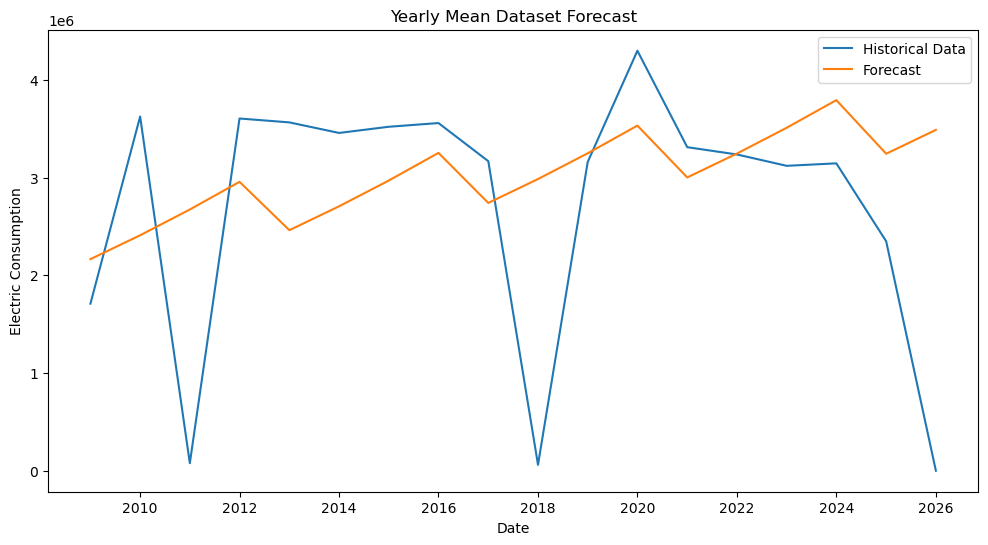

14:05:15 - cmdstanpy - INFO - Chain [1] start processing
14:05:15 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 1 year(s)


,ds,yhat,yhat_lower,yhat_upper
18,2027-01-01,2.558334e+06,1.048556e+06,4.146397e+06


14:05:15 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 10 year(s)


14:05:15 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
18,2027-01-01,2.558334e+06,9.352387e+05,4.138189e+06
19,2028-01-01,2.839827e+06,1.209083e+06,4.412786e+06
20,2029-01-01,1.848972e+06,3.838838e+05,3.405933e+06
21,2030-01-01,2.048912e+06,5.447362e+05,3.727270e+06
22,2031-01-01,2.289776e+06,6.600731e+05,3.842775e+06
23,2032-01-01,2.571268e+06,9.456328e+05,4.226770e+06
24,2033-01-01,1.512059e+06,-1.543012e+05,2.986229e+06
25,2034-01-01,1.712000e+06,1.936096e+05,3.218398e+06
26,2035-01-01,1.952863e+06,4.432126e+05,3.662607e+06
27,2036-01-01,2.234356e+06,6.134938e+05,3.696583e+06


14:05:15 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 20 year(s)


14:05:15 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
18,2027-01-01,2.558334e+06,9.144604e+05,4.224977e+06
19,2028-01-01,2.839827e+06,1.316143e+06,4.329841e+06
20,2029-01-01,1.848972e+06,2.764897e+05,3.360785e+06
21,2030-01-01,2.048912e+06,4.723273e+05,3.604858e+06
22,2031-01-01,2.289776e+06,7.228547e+05,3.783419e+06
23,2032-01-01,2.571268e+06,9.544195e+05,4.142389e+06
24,2033-01-01,1.512059e+06,2.265999e+04,3.045323e+06
25,2034-01-01,1.712000e+06,7.217301e+04,3.272635e+06
26,2035-01-01,1.952863e+06,3.434380e+05,3.708272e+06
27,2036-01-01,2.234356e+06,6.406215e+05,3.983563e+06


In [38]:
run_dataset(daily_df, "Daily Dataset")
run_dataset(monthly_df, "Monthly Mean Dataset")
run_dataset(yearly_df, "Yearly Mean Dataset")

## Extra Credit 1: Forecast Each Borough Independently

This section creates a daily dataset for each borough and applies forecasting separately.

In [39]:
borough_names = df["Borough"].dropna().unique()
print(borough_names)

['BROOKLYN' 'MANHATTAN' 'QUEENS' 'BRONX' 'STATEN ISLAND'
 'NON DEVELOPMENT FACILITY' 'FHA']



Borough: BROOKLYN


13:59:39 - cmdstanpy - INFO - Chain [1] start processing



Dataset: BROOKLYN Daily Dataset
Detected time unit: day


13:59:40 - cmdstanpy - INFO - Chain [1] done processing
13:59:40 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
Optimization terminated abnormally. Falling back to Newton.
13:59:40 - cmdstanpy - INFO - Chain [1] start processing
13:59:43 - cmdstanpy - INFO - Chain [1] done processing
13:59:43 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 7, 'fourier': 5, 'changepoints': 10, 'cps': 0.05}
MAE: 432257.2009765763
MAPE: 39807385561779.34
R2: 0.05784265406012534


13:59:44 - cmdstanpy - INFO - Chain [1] done processing
13:59:45 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 396841.1494610575
MAPE: 52947973543549.266
R2: 0.16642750791953853


13:59:46 - cmdstanpy - INFO - Chain [1] done processing
13:59:51 - cmdstanpy - INFO - Chain [1] start processing
13:59:51 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 295980.992528518
MAPE: 89361575814033.11
R2: 0.3115147404394929

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 337794.2674919524
MAPE: 118711586739173.78
R2: 0.07214463025890783

Best Parameters for BROOKLYN Daily Dataset
{'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
Best MAE: 295980.992528518
Best MAPE: 89361575814033.11
Best R2: 0.3115147404394929


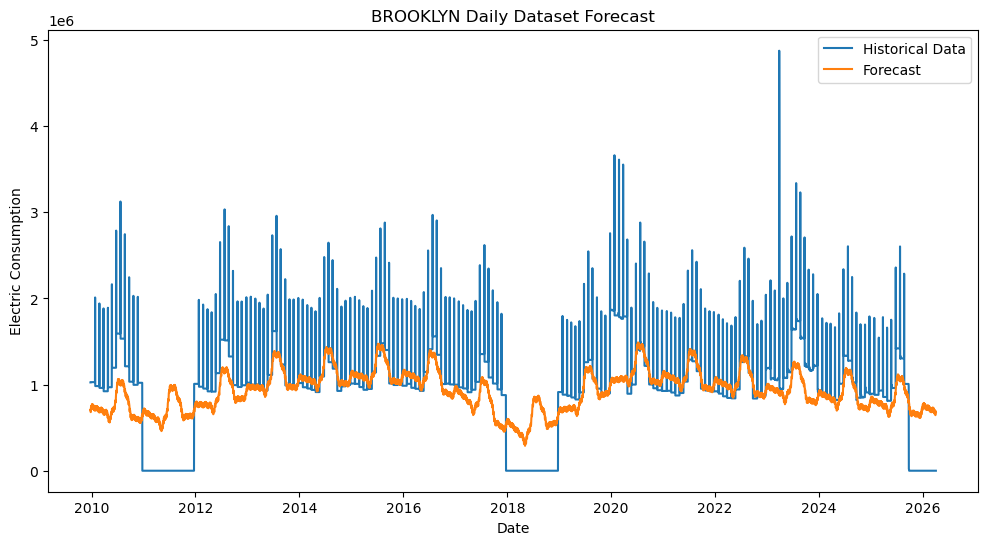


Forecast for next 100 day(s)


13:59:52 - cmdstanpy - INFO - Chain [1] start processing
13:59:52 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5943,2026-04-02,8.793587e+05,277153.026405,1.466979e+06
5944,2026-04-03,8.742151e+05,296703.248726,1.434253e+06
5945,2026-04-04,8.377072e+05,308616.652095,1.454360e+06
5946,2026-04-05,8.406307e+05,237148.371435,1.425698e+06
5947,2026-04-06,8.923316e+05,307129.963992,1.493223e+06
...,...,...,...,...
6038,2026-07-06,1.307756e+06,720874.079118,1.903395e+06
6039,2026-07-07,1.312531e+06,699301.751951,1.882215e+06
6040,2026-07-08,1.298690e+06,721895.379810,1.830433e+06
6041,2026-07-09,1.311677e+06,658525.791189,1.906477e+06


13:59:58 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 200 day(s)


13:59:58 - cmdstanpy - INFO - Chain [1] done processing


... (8 outputs left out)

14:00:13 - cmdstanpy - INFO - Chain [1] done processing
14:00:14 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 353644.4037846374
MAPE: 85.05517347212512
R2: -1.6100828442277701


14:00:14 - cmdstanpy - INFO - Chain [1] done processing
14:00:19 - cmdstanpy - INFO - Chain [1] start processing
14:00:19 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 347615.26762986055
MAPE: 2204.331598111269
R2: -0.9884498579360692

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 168613.99791492676
MAPE: 1169.9397546373755
R2: 0.2820545884834965

Best Parameters for MANHATTAN Daily Dataset
{'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
Best MAE: 168613.99791492676
Best MAPE: 1169.9397546373755
Best R2: 0.2820545884834965


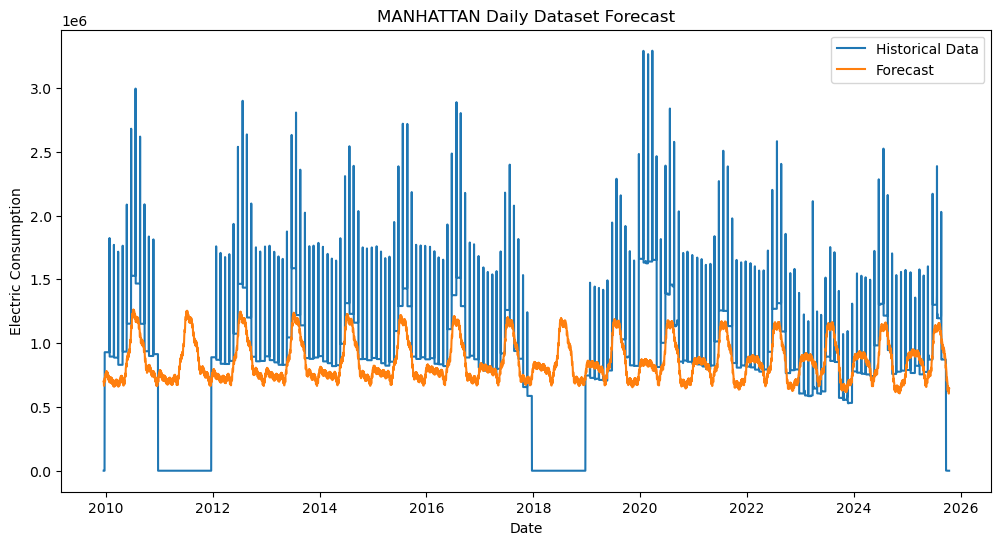

14:00:20 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 100 day(s)


14:00:20 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5781,2025-10-15,619255.110780,104540.327230,1.121020e+06
5782,2025-10-16,635227.216752,116473.807798,1.180137e+06
5783,2025-10-17,634904.861219,128759.248806,1.149596e+06
5784,2025-10-18,606078.624771,113564.888833,1.123885e+06
5785,2025-10-19,612726.105067,145244.590139,1.153899e+06
...,...,...,...,...
5876,2026-01-18,806328.074899,286182.136125,1.364226e+06
5877,2026-01-19,846245.590101,320592.393641,1.384625e+06
5878,2026-01-20,845407.567922,294441.596876,1.373889e+06
5879,2026-01-21,832571.950977,311695.720498,1.348799e+06


14:00:20 - cmdstanpy - INFO - Chain [1] start processing
14:00:20 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 200 day(s)


... (8 outputs left out)

14:00:23 - cmdstanpy - INFO - Chain [1] done processing
14:00:24 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 124794.4394572464
MAPE: 7.44905202396842e+17
R2: -0.7470047172636456


14:00:24 - cmdstanpy - INFO - Chain [1] done processing
14:00:29 - cmdstanpy - INFO - Chain [1] start processing
14:00:29 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 72929.71527472457
MAPE: 2.9934802720694436e+18
R2: 0.1518554941847049

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 76813.13283336331
MAPE: 2.5668274649388457e+18
R2: 0.06373468190149145

Best Parameters for QUEENS Daily Dataset
{'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
Best MAE: 72929.71527472457
Best MAPE: 2.9934802720694436e+18
Best R2: 0.1518554941847049


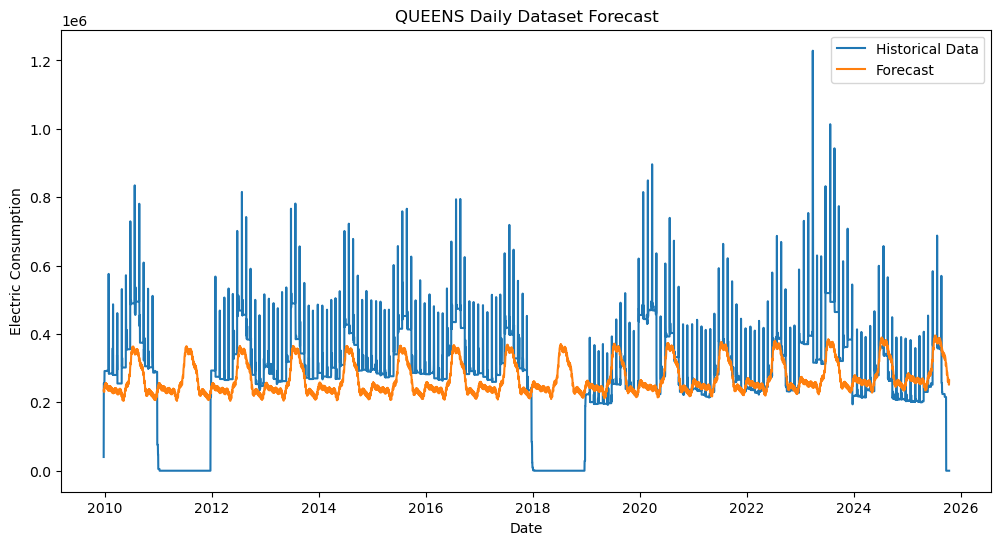


Forecast for next 100 day(s)


14:00:30 - cmdstanpy - INFO - Chain [1] start processing
14:00:30 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5774,2025-10-14,233550.128506,71675.359096,391682.499229
5775,2025-10-15,230910.977686,59932.874014,385939.932775
5776,2025-10-16,235498.061797,60342.615572,399571.883707
5777,2025-10-17,235708.687070,64023.139461,417093.640778
5778,2025-10-18,226884.041974,55218.404059,388199.992952
...,...,...,...,...
5869,2026-01-17,246097.815966,78476.748679,406431.164533
5870,2026-01-18,245393.261639,75897.858587,422250.122466
5871,2026-01-19,258350.662597,85021.386910,418267.033728
5872,2026-01-20,258085.710018,99145.537326,426818.818129



Forecast for next 200 day(s)


14:00:36 - cmdstanpy - INFO - Chain [1] start processing
14:00:37 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5774,2025-10-14,233550.128506,73403.364194,397813.199075
5775,2025-10-15,230910.977686,66673.512669,396648.997563
5776,2025-10-16,235498.061797,70881.370515,399767.775601
5777,2025-10-17,235708.687070,78614.958620,407516.537684
5778,2025-10-18,226884.041974,58366.012410,386983.769316
...,...,...,...,...
5969,2026-04-27,238018.907157,65434.160162,390353.363492
5970,2026-04-28,237050.975119,83044.538918,418290.703167
5971,2026-04-29,231483.969001,73498.773698,391355.534842
5972,2026-04-30,233102.727348,58361.016675,394413.398495


... (7 outputs left out)

14:00:55 - cmdstanpy - INFO - Chain [1] done processing
14:00:56 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 304218.06597199733
MAPE: 372.9898517492158
R2: -1.5680430315007912


14:00:56 - cmdstanpy - INFO - Chain [1] done processing
14:01:02 - cmdstanpy - INFO - Chain [1] start processing
14:01:02 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 131509.0473130316
MAPE: 1108.008825423949
R2: 0.28295885111438845

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 143927.26238862236
MAPE: 988.926647837574
R2: 0.27433796352882356

Best Parameters for BRONX Daily Dataset
{'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
Best MAE: 131509.0473130316
Best MAPE: 1108.008825423949
Best R2: 0.28295885111438845


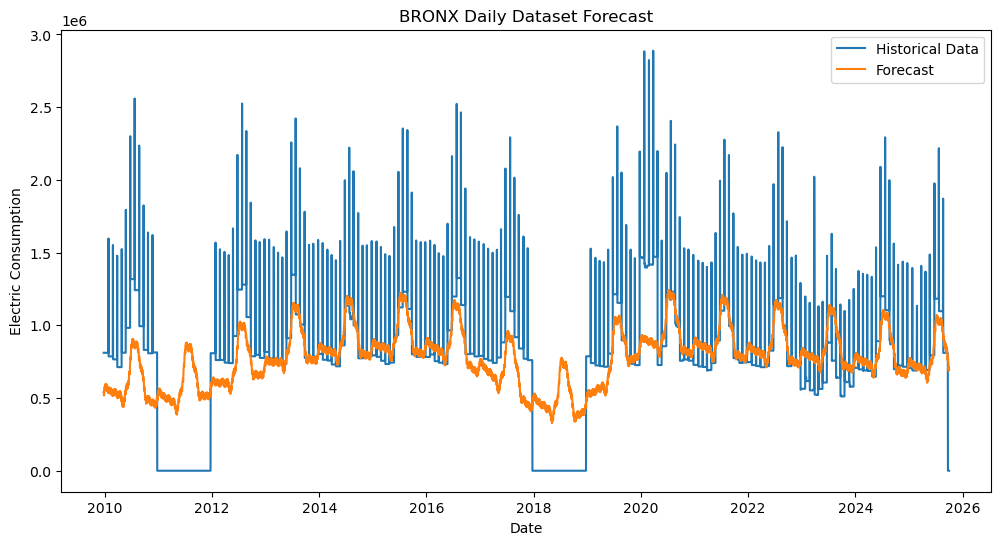


Forecast for next 100 day(s)


14:01:03 - cmdstanpy - INFO - Chain [1] start processing
14:01:03 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5761,2025-10-02,679800.017025,238951.216319,1.119652e+06
5762,2025-10-03,667748.491530,156061.725776,1.108716e+06
5763,2025-10-04,631612.223274,162968.265802,1.076111e+06
5764,2025-10-05,628579.728809,180002.599678,1.078743e+06
5765,2025-10-06,664459.473947,219427.848091,1.123876e+06
...,...,...,...,...
5856,2026-01-05,747611.551248,320438.567994,1.203368e+06
5857,2026-01-06,748864.483180,278939.615717,1.215784e+06
5858,2026-01-07,738033.858100,263115.974388,1.184324e+06
5859,2026-01-08,747018.232294,311740.239311,1.172405e+06


14:01:09 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 200 day(s)


14:01:09 - cmdstanpy - INFO - Chain [1] done processing


... (9 outputs left out)

14:01:26 - cmdstanpy - INFO - Chain [1] done processing
14:01:26 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 41599.418359623494
MAPE: 49.07354784476551
R2: -0.5831113439007807


14:01:27 - cmdstanpy - INFO - Chain [1] done processing
14:01:33 - cmdstanpy - INFO - Chain [1] start processing
14:01:33 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 26714.381045685688
MAPE: 164.1750515077231
R2: -0.10486623432349962

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 27722.895086844223
MAPE: 167.49958077614377
R2: -0.02316349477461155

Best Parameters for STATEN ISLAND Daily Dataset
{'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
Best MAE: 26714.381045685688
Best MAPE: 164.1750515077231
Best R2: -0.10486623432349962


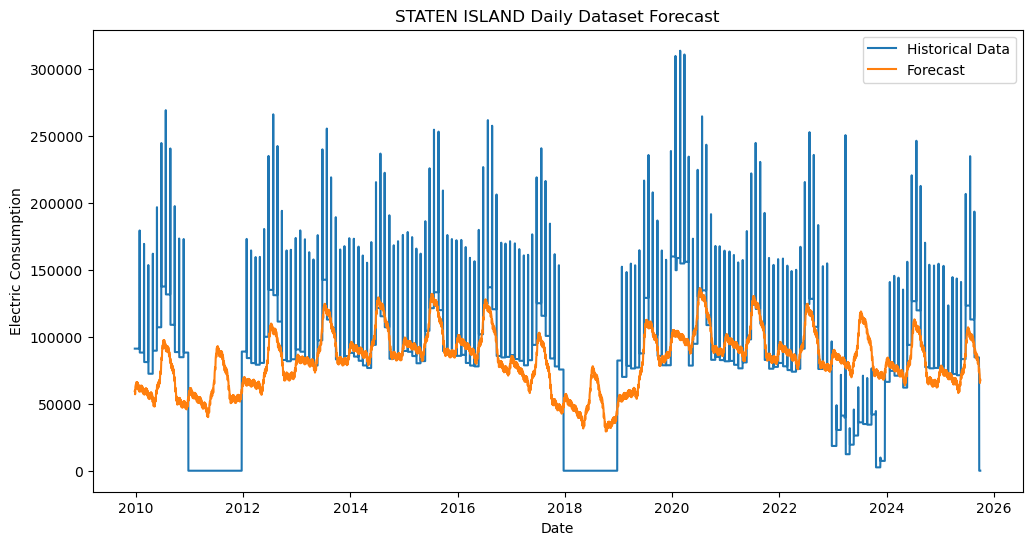


Forecast for next 100 day(s)


14:01:33 - cmdstanpy - INFO - Chain [1] start processing
14:01:33 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5760,2025-10-01,72254.500296,17239.214949,124010.220114
5761,2025-10-02,72471.203047,19243.625373,126877.355355
5762,2025-10-03,71245.173733,18933.934905,122811.324200
5763,2025-10-04,67372.714230,20189.394052,121411.468937
5764,2025-10-05,67025.564359,16716.724856,120009.031799
...,...,...,...,...
5855,2026-01-04,74478.188979,22890.839776,121846.068701
5856,2026-01-05,78630.985723,25337.645646,132298.261198
5857,2026-01-06,78817.817656,25503.471262,130175.962217
5858,2026-01-07,77744.679300,26316.847782,131014.175981


14:01:39 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 200 day(s)


14:01:39 - cmdstanpy - INFO - Chain [1] done processing


... (9 outputs left out)

14:01:55 - cmdstanpy - INFO - Chain [1] done processing
14:01:55 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 39925.21406938639
MAPE: 15.717035084336954
R2: -2.1300890558508367


14:01:56 - cmdstanpy - INFO - Chain [1] done processing
14:02:01 - cmdstanpy - INFO - Chain [1] start processing
14:02:01 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 22822.302492049632
MAPE: 22.267473275214876
R2: -0.05096417781432727

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 24513.84625542254
MAPE: 23.477583136226972
R2: -0.30257796436299156

Best Parameters for NON DEVELOPMENT FACILITY Daily Dataset
{'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
Best MAE: 22822.302492049632
Best MAPE: 22.267473275214876
Best R2: -0.05096417781432727


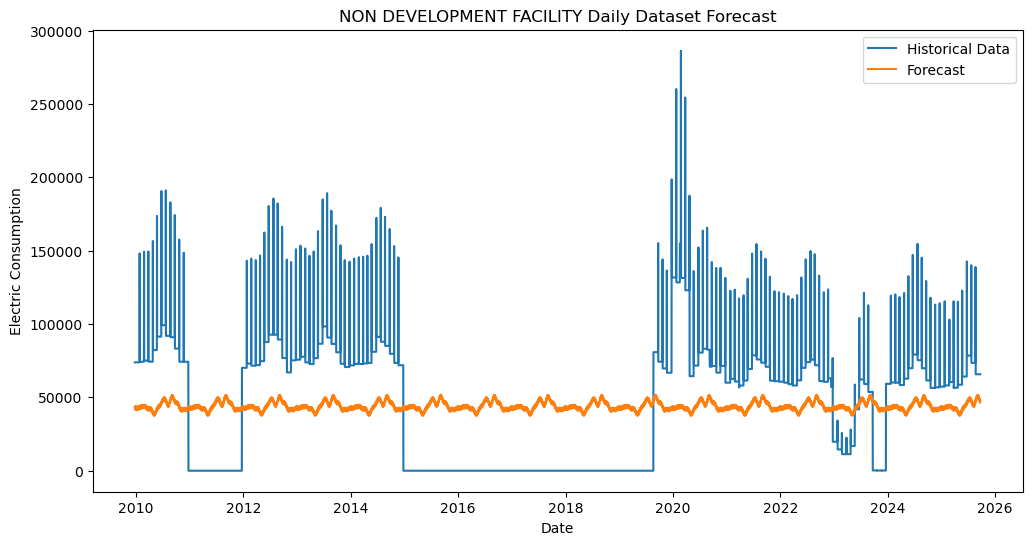


Forecast for next 100 day(s)


14:02:02 - cmdstanpy - INFO - Chain [1] start processing
14:02:03 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
5752,2025-09-23,77392.471758,37562.308734,120792.569696
5753,2025-09-24,76544.212757,36229.429943,116377.185421
5754,2025-09-25,76699.338538,36063.962507,117407.708269
5755,2025-09-26,76184.316305,33280.758749,119407.141198
5756,2025-09-27,73878.393497,33267.774298,114316.891329
...,...,...,...,...
5847,2025-12-27,70177.091156,30462.528437,111938.909477
5848,2025-12-28,70222.370760,28216.455212,108658.201869
5849,2025-12-29,72174.539844,32082.031610,117866.959734
5850,2025-12-30,72571.484973,30675.702927,117917.570572


14:02:08 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 200 day(s)


14:02:09 - cmdstanpy - INFO - Chain [1] done processing


... (9 outputs left out)

14:02:23 - cmdstanpy - INFO - Chain [1] done processing
14:02:23 - cmdstanpy - INFO - Chain [1] start processing



Parameters: {'growth': 'linear', 'period': 30.5, 'fourier': 5, 'changepoints': 20, 'cps': 0.1}
MAE: 11737.6186944132
MAPE: 33.71479361768115
R2: -0.18235698826890734


14:02:26 - cmdstanpy - INFO - Chain [1] done processing
14:02:30 - cmdstanpy - INFO - Chain [1] start processing
14:02:30 - cmdstanpy - INFO - Chain [1] done processing



Parameters: {'growth': 'logistic', 'period': 7, 'fourier': 10, 'changepoints': 15, 'cps': 0.05}
MAE: 22563.0328329403
MAPE: 248.7463339514555
R2: -1.1932793978483964

Parameters: {'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
MAE: 10567.546811919368
MAPE: 7.10980479315998
R2: -0.2917925259164402

Best Parameters for FHA Daily Dataset
{'growth': 'flat', 'period': 365, 'fourier': 3, 'changepoints': 10, 'cps': 0.01}
Best MAE: 10567.546811919368
Best MAPE: 7.10980479315998
Best R2: -0.2917925259164402


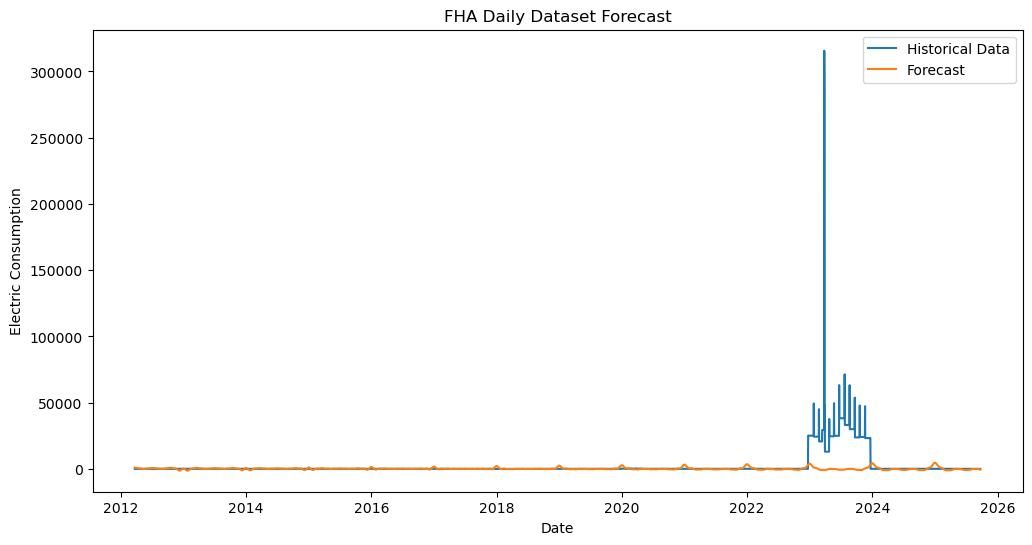

14:02:31 - cmdstanpy - INFO - Chain [1] start processing



Forecast for next 100 day(s)


14:02:31 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
4933,2025-09-23,2317.815458,-9965.114575,14233.141153
4934,2025-09-24,1902.671220,-9089.506457,13866.854152
4935,2025-09-25,1926.720953,-10030.021211,13298.709496
4936,2025-09-26,1837.279416,-10309.004950,14159.793272
4937,2025-09-27,1737.103816,-9560.512366,15441.652093
...,...,...,...,...
5028,2025-12-27,466.521983,-10995.715461,11475.656835
5029,2025-12-28,491.680776,-11163.916841,12153.540158
5030,2025-12-29,1009.251991,-11559.735591,13931.819635
5031,2025-12-30,1028.265120,-11816.207528,12687.722173


14:02:31 - cmdstanpy - INFO - Chain [1] start processing
14:02:31 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 200 day(s)


,ds,yhat,yhat_lower,yhat_upper
4933,2025-09-23,2317.815458,-10039.873130,14785.423610
4934,2025-09-24,1902.671220,-10358.719433,14066.924515
4935,2025-09-25,1926.720953,-9614.877096,13740.216136
4936,2025-09-26,1837.279416,-10580.028364,14098.926458
4937,2025-09-27,1737.103816,-10138.817835,13107.467298
...,...,...,...,...
5128,2026-04-06,3115.487943,-8970.824363,14934.391294
5129,2026-04-07,2833.864354,-8682.112255,14289.729915
5130,2026-04-08,2174.832738,-10027.402229,14358.326642
5131,2026-04-09,1965.301366,-9723.501296,14271.767584


14:02:32 - cmdstanpy - INFO - Chain [1] start processing
14:02:32 - cmdstanpy - INFO - Chain [1] done processing



Forecast for next 365 day(s)


,ds,yhat,yhat_lower,yhat_upper
4933,2025-09-23,2317.815458,-9911.601639,14783.908931
4934,2025-09-24,1902.671220,-10353.686161,13314.474875
4935,2025-09-25,1926.720953,-11458.081846,14102.073931
4936,2025-09-26,1837.279416,-9462.927942,14403.002169
4937,2025-09-27,1737.103816,-10079.780120,13542.964899
...,...,...,...,...
5293,2026-09-18,1965.666741,-9469.143786,13301.877684
5294,2026-09-19,1883.238168,-9737.341364,14454.035781
5295,2026-09-20,1870.455803,-10513.884347,14435.852520
5296,2026-09-21,2344.265179,-10103.882141,14239.115502


In [21]:
def build_borough_daily_series(interval_df, borough_name):
    borough_df = interval_df[interval_df["Borough"] == borough_name].copy()

    temp = borough_df[["Service Start Date", "Service End Date", "daily_kwh"]].copy()

    start_add = temp.groupby("Service Start Date")["daily_kwh"].sum()

    end_sub = temp.assign(
        end_next=temp["Service End Date"] + pd.Timedelta(days=1)
    ).groupby("end_next")["daily_kwh"].sum()

    deltas = start_add.subtract(end_sub, fill_value=0).sort_index()

    full_dates = pd.date_range(
        temp["Service Start Date"].min(),
        temp["Service End Date"].max(),
        freq="D"
    )

    daily_series = deltas.reindex(full_dates, fill_value=0).cumsum()

    borough_daily = daily_series.reset_index()
    borough_daily.columns = ["ds", "y"]
    borough_daily["y"] = borough_daily["y"].clip(lower=0)

    return borough_daily

for borough in borough_names:
    print("\n==============================")
    print("Borough:", borough)
    print("==============================")

    borough_daily = build_borough_daily_series(df, borough)
    run_dataset(borough_daily, borough + " Daily Dataset")

## Extra Credit 2: ACF Correlogram

This section creates ACF plots for:
1. The entire NYC daily dataset
2. Each borough daily dataset

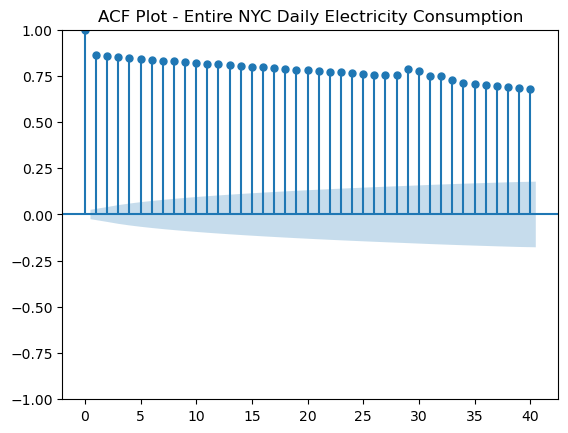

In [24]:
plot_acf(daily_df["y"], lags=40)
plt.title("ACF Plot - Entire NYC Daily Electricity Consumption")
plt.show()

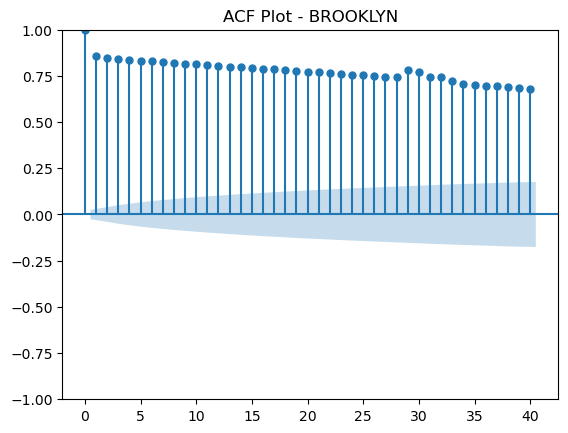

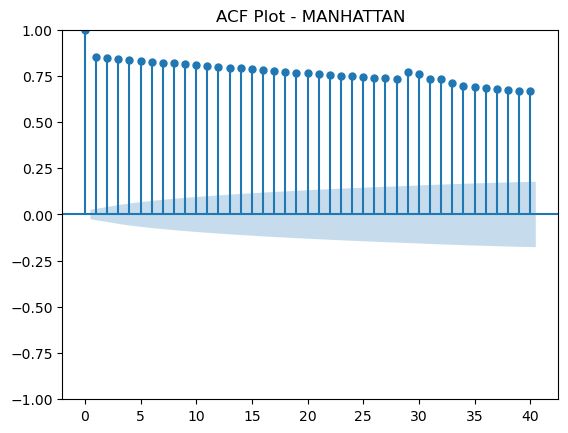

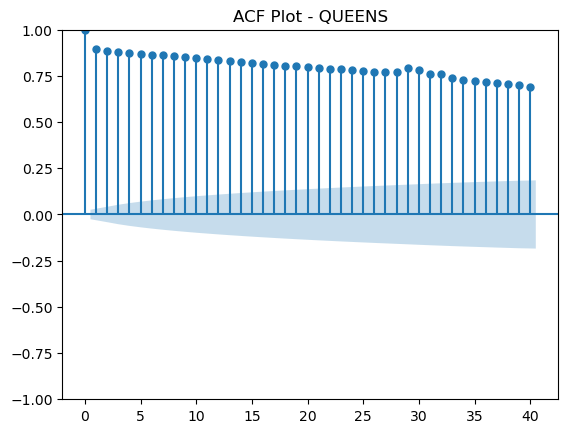

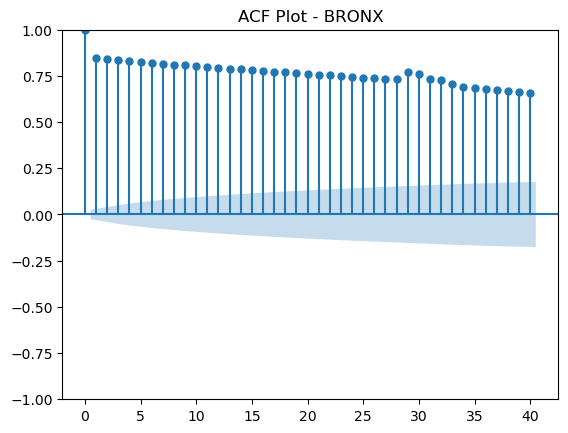

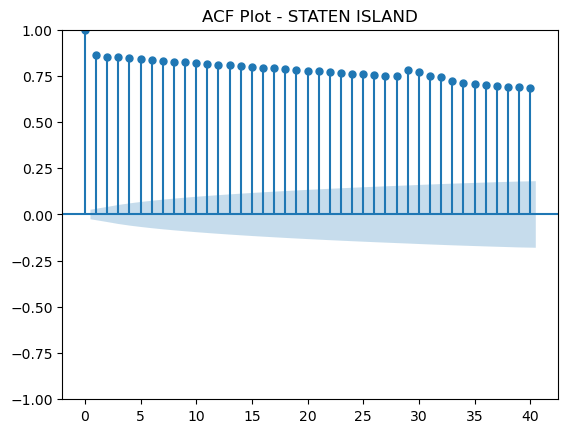

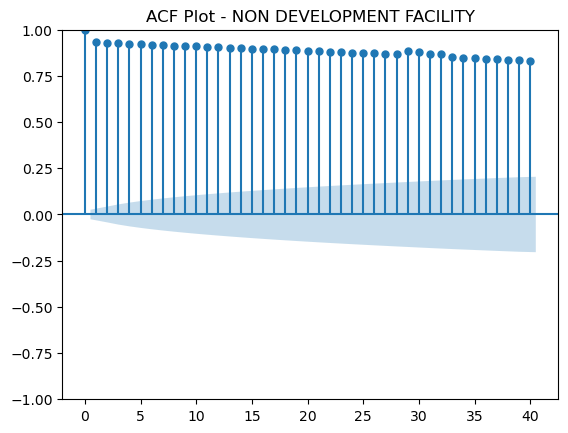

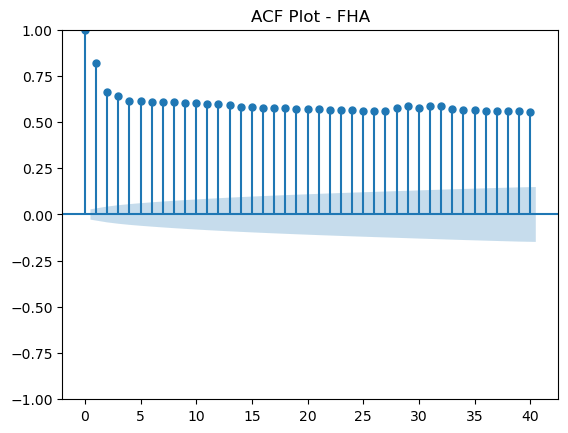

In [25]:
for borough in borough_names:
    borough_daily = build_borough_daily_series(df, borough)

    plot_acf(borough_daily["y"], lags=40)
    plt.title("ACF Plot - " + borough)
    plt.show()

## Observations

- The daily dataset had more fluctuation and short-term variation.
- The monthly mean dataset was smoother because it averaged daily values over each month.
- The yearly mean dataset was the smoothest, but it had fewer observations.
- Different Prophet parameter values produced different forecast results.
- Forecasting became easier to interpret when the data was aggregated from daily to monthly and yearly.

## Limitations Faced

- The raw dataset was billing-period data, so it had to be converted into a true daily time series first.
- The electricity consumption column required cleaning because values contained commas.
- Daily data had higher variability and noise, which made forecasting more difficult.
- Yearly data had fewer data points, so the model had less information to learn from.
- Parameter tuning required trial and error because different Prophet settings performed differently on each dataset.

## Conclusion

In this project, I implemented a time series forecasting model using Prophet for NYC electricity consumption.
I tested the model on daily, monthly mean, and yearly mean datasets.
I also created code that automatically detects the time unit, forecasts future values based on that unit, tunes Prophet parameters, and evaluates the model using MAE, MAPE, and R².

For extra credit, I also forecasted electricity consumption for each borough independently and generated ACF correlograms.
Overall, Prophet worked well for this forecasting problem, especially on the smoother monthly and yearly datasets.